<a href="https://colab.research.google.com/github/Niklas-Hy/Deeplearning/blob/main/Exercise_7_1_CIFAR_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tabulate import tabulate
layers = tf.keras.layers

The code block below defines a few helper functions to visualize the results. You do not need to touch them.

In [2]:
def plot_examples(X, Y, n=10):
    """ Plot the first n examples for each of the 10 classes in the CIFAR dataset X, Y """
    fig, axes = plt.subplots(n, 10, figsize=(10, n))
    for l in range(10):
        axes[0, l].set_title(cifar10_labels[l], fontsize="smaller")
        m = np.squeeze(Y) == l  # boolean mask: True for all images of label l
        for i in range(n):
            image = X[m][i].astype("uint8")  # imshow expects uint8
            ax = axes[i, l]
            ax.imshow(image, origin="upper")
            ax.set(xticks=[], yticks=[])
    return fig, ax


def plot_prediction(X, Y, Y_predict):
    """
    Plot image X along with predicted probabilities Y_predict.
    X: CIFAR image, shape = (32, 32, 3)
    Y: CIFAR label, one-hot encoded, shape = (10)
    Y_predict: predicted probabilities, shape = (10)
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

    # plot image
    ax1.imshow(X.astype("uint8"), origin="upper")
    ax1.set(xticks=[], yticks=[])

    # plot probabilities
    ax2.barh(np.arange(10), Y_predict, align="center")
    ax2.set(xlim=(0, 1), xlabel="Score", yticks=[])
    for i in range(10):
        c = "red" if (i == np.argmax(Y)) else "black"
        ax2.text(0.05, i, cifar10_labels[i].capitalize(), ha="left", va="center", color=c)



def plot_confusion(Y_true, Y_predict):
    """
    Plot confusion matrix
    Y_true:    array of true classifications (0-9), shape = (N)
    Y_predict: array of predicted classifications (0-9), shape = (N)
    """
    C = np.histogram2d(Y_true, Y_predict, bins=np.linspace(-0.5, 9.5, 11))[0]
    Cn = C / np.sum(C, axis=1)

    fig = plt.figure()
    plt.imshow(Cn, interpolation="nearest", vmin=0, vmax=1, cmap=plt.cm.YlGnBu)
    plt.colorbar()
    plt.xlabel("prediction")
    plt.ylabel("truth")
    plt.xticks(range(10), cifar10_labels, rotation="vertical")
    plt.yticks(range(10), cifar10_labels)
    for x in range(10):
        for y in range(10):
            plt.annotate("%i" % C[x, y], xy=(y, x), ha="center", va="center")



First we load and preprocess CIFAR-10 data. The imagages are 32x32 pixels and have three color channels (red, green blue).

In [3]:

# X: images, Y: labels
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("images, shape = ", x_train.shape)
print("labels, shape = ", y_train.shape)

cifar10_labels = np.array([
    'airplane',
    'automobile',
    'bird',
    'cat',
    'deer',
    'dog',
    'frog',
    'horse',
    'ship',
    'truck'])

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1635s 10us/step
images, shape =  (50000, 32, 32, 3)
labels, shape =  (50000, 1)


(<Figure size 1000x1000 with 100 Axes>, <Axes: >)

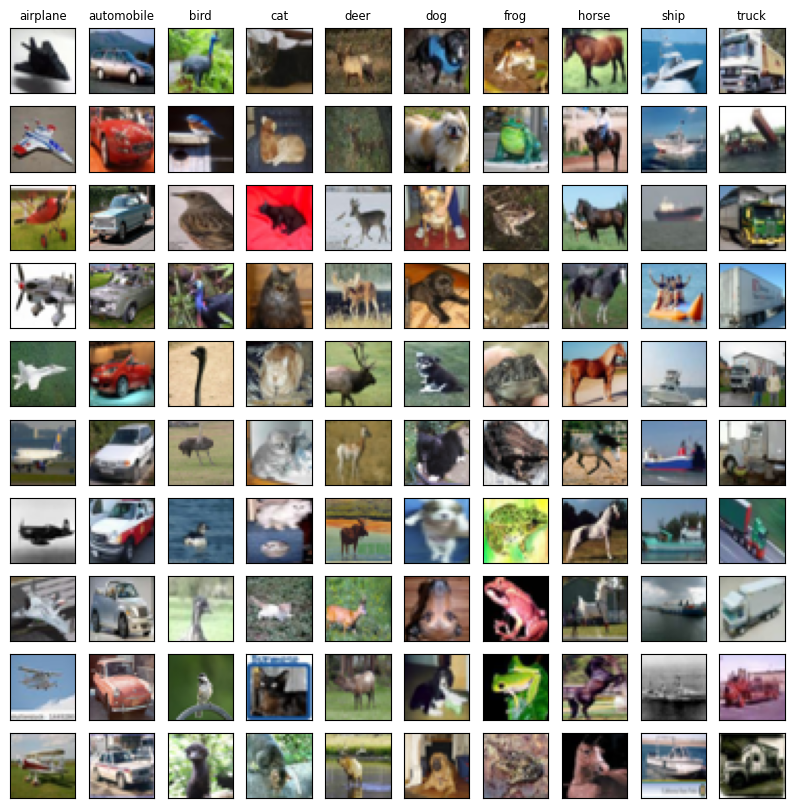

In [4]:
# Hint: To plot example images, you can use the plot examples function
plot_examples(x_train, y_train)








In [7]:
y_train_onehot = tf.keras.utils.to_categorical(y_train, 10)
y_test_onehot = tf.keras.utils.to_categorical(y_test, 10)[:8000]
y_valid_onehot = tf.keras.utils.to_categorical(y_test, 10)[8000:]

x_train_norm = x_train / 255.0
x_test_norm = x_test[:8000] / 255.0
x_valid_norm = x_test[8000:] / 255.0   # last 20% of test data = validation



We start with a fully connected network

In [16]:
# ----------------------------------------------------------
# Define model
# ----------------------------------------------------------
model = tf.keras.models.Sequential(
  [
    layers.Flatten(input_shape=(32, 32, 3)),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax"),
  ],
  name="nn",
)
print(model.summary())



/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "nn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 855,050 (3.26 MB)

 Trainable params: 855,050 (3.26 MB)

 Non-trainable params: 0 (0.00 B)

None


In [17]:
# ----------------------------------------------------------
# Training
# ----------------------------------------------------------
model.compile(

  loss="categorical_crossentropy",
  optimizer=tf.keras.optimizers.Adam(1e-3),
  metrics=["accuracy"],

)

model.fit(
    x_train_norm, y_train_onehot,
    batch_size=128,
    epochs=20, # train at least for 20 epochs
    verbose=2,
    validation_data=(x_valid_norm, y_valid_onehot),
    callbacks=[tf.keras.callbacks.CSVLogger("history_{}.csv".format(model.name))],
)

Epoch 1/20
391/391 - 6s - 16ms/step - accuracy: 0.2630 - loss: 2.0037 - val_accuracy: 0.3320 - val_loss: 1.8693
Epoch 2/20
391/391 - 1s - 3ms/step - accuracy: 0.3097 - loss: 1.8861 - val_accuracy: 0.3580 - val_loss: 1.7832
Epoch 3/20
391/391 - 1s - 3ms/step - accuracy: 0.3320 - loss: 1.8307 - val_accuracy: 0.3870 - val_loss: 1.7191
Epoch 4/20
391/391 - 1s - 3ms/step - accuracy: 0.3409 - loss: 1.8064 - val_accuracy: 0.3950 - val_loss: 1.7211
Epoch 5/20
391/391 - 1s - 3ms/step - accuracy: 0.3551 - loss: 1.7698 - val_accuracy: 0.3915 - val_loss: 1.7103
Epoch 6/20
391/391 - 1s - 3ms/step - accuracy: 0.3621 - loss: 1.7544 - val_accuracy: 0.3985 - val_loss: 1.6829
Epoch 7/20
391/391 - 1s - 4ms/step - accuracy: 0.3628 - loss: 1.7498 - val_accuracy: 0.3855 - val_loss: 1.6723
Epoch 8/20
391/391 - 2s - 4ms/step - accuracy: 0.3688 - loss: 1.7311 - val_accuracy: 0.3860 - val_loss: 1.6793
Epoch 9/20
391/391 - 1s - 3ms/step - accuracy: 0.3777 - loss: 1.7152 - val_accuracy: 0.4170 - val_loss: 1.6696


In [18]:
for name, x, y in [("train", x_train_norm, y_train_onehot),
                   ("valid", x_valid_norm, y_valid_onehot),
                   ("test", x_test_norm, y_test_onehot)]:
  loss, acc = model.evaluate(x, y, batch_size=512, verbose=0)
  print(f"{model.name} {name} accuracy: {acc:.3f}")

nn train accuracy: 0.455
nn valid accuracy: 0.431
nn test accuracy: 0.437


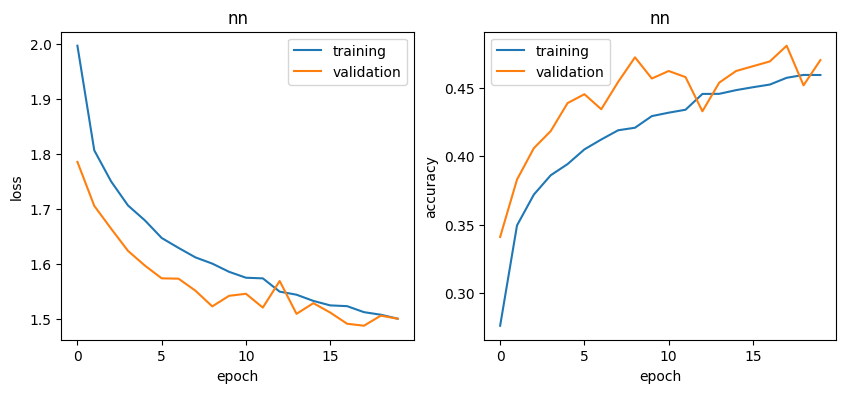

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
test accuracy: 0.483875


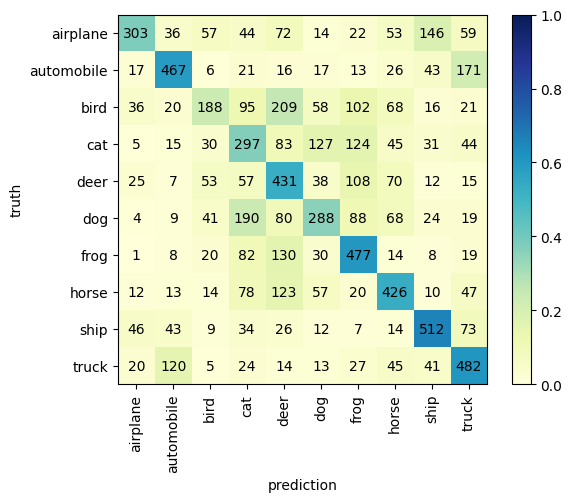

In [10]:
# ----------------------------------------------------------
# Plots
# ----------------------------------------------------------
# training curves
history = np.genfromtxt("history_{}.csv".format(model.name), delimiter=",", names=True)


# Hint: this is how you can plot the confusion matrix.
# calculate predictions for test set

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(history["epoch"], history["loss"], label="training")
ax1.plot(history["epoch"], history["val_loss"], label="validation")
ax1.set(xlabel="epoch", ylabel="loss", title=model.name)
ax1.legend()
ax2.plot(history["epoch"], history["accuracy"], label="training")
ax2.plot(history["epoch"], history["val_accuracy"], label="validation")
ax2.set(xlabel="epoch", ylabel="accuracy", title=model.name)
ax2.legend()
plt.show()

y_predict = model.predict(x_test_norm, batch_size=128)


# convert back to class labels (0-9)

y_predict_cl = np.argmax(y_predict, axis=1)
y_test_cl = np.argmax(y_test_onehot, axis=1)

# plot confusion matrix


print("test accuracy:", np.mean(y_predict_cl == y_test_cl))
plot_confusion(y_test_cl, y_predict_cl)

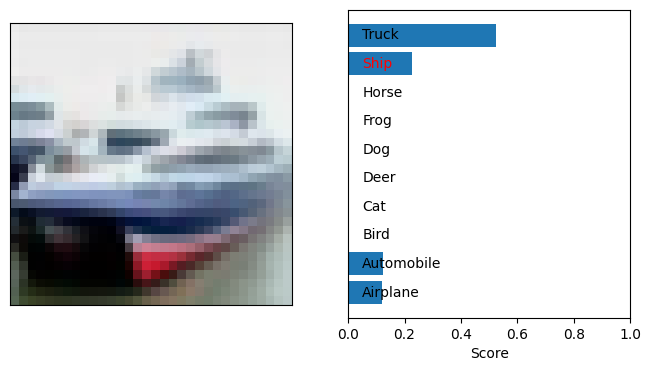

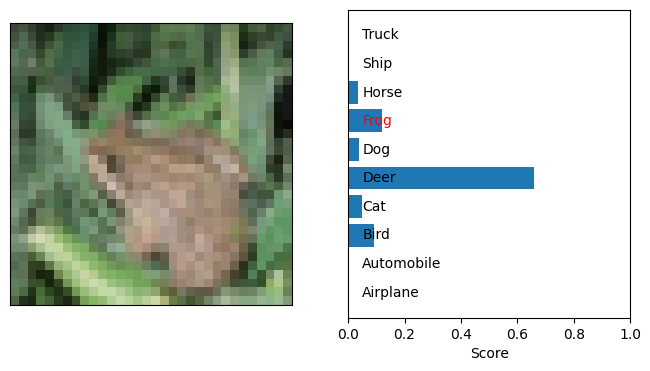

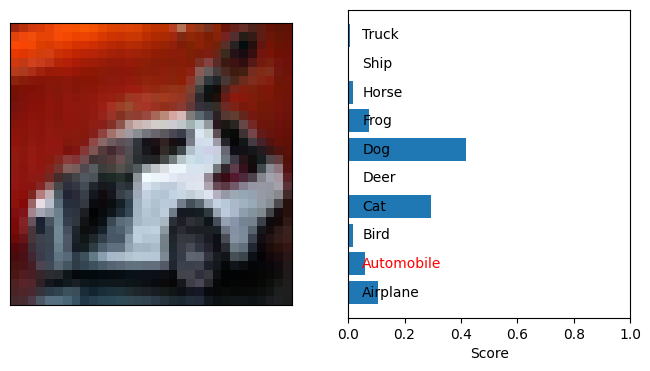

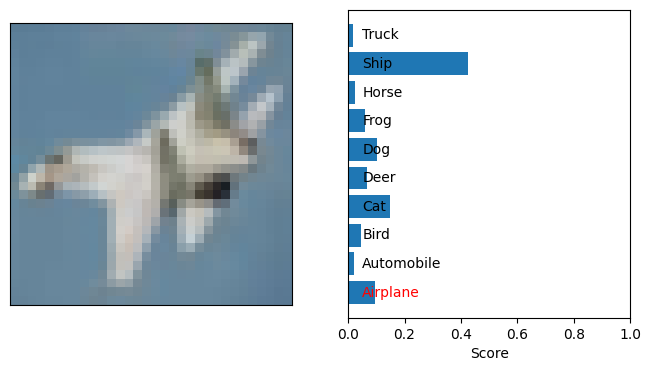

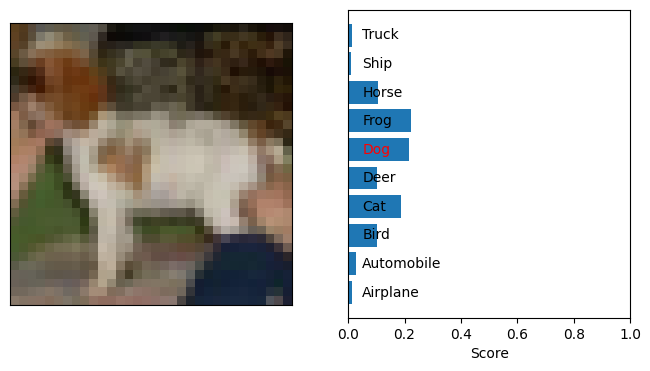

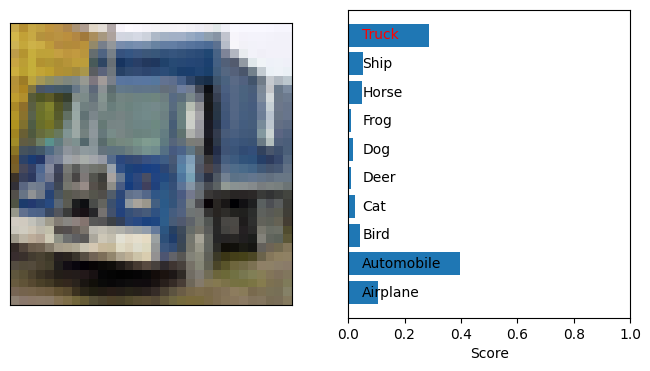

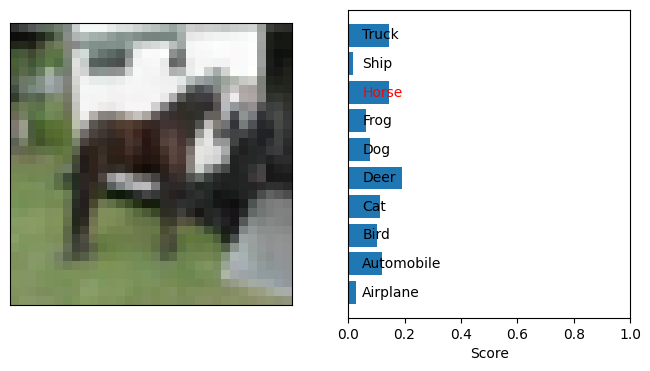

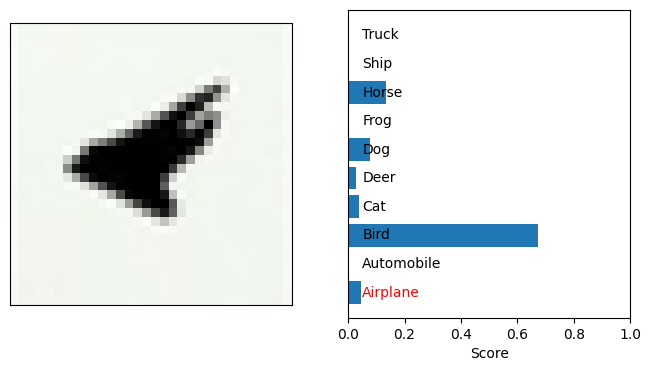

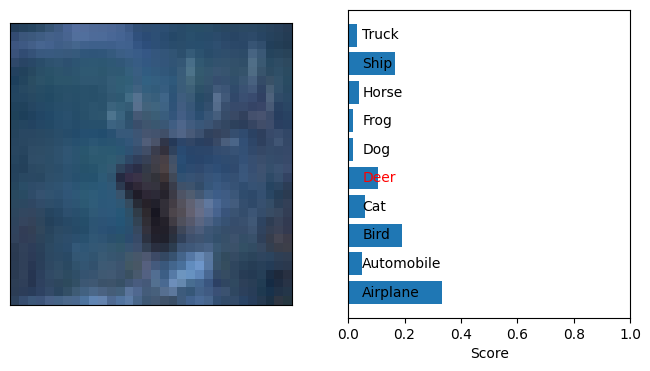

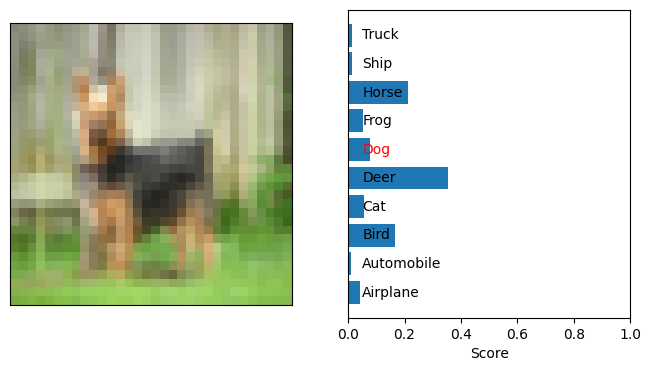

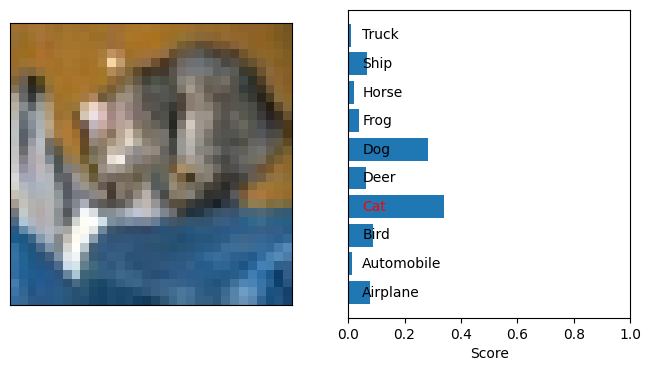

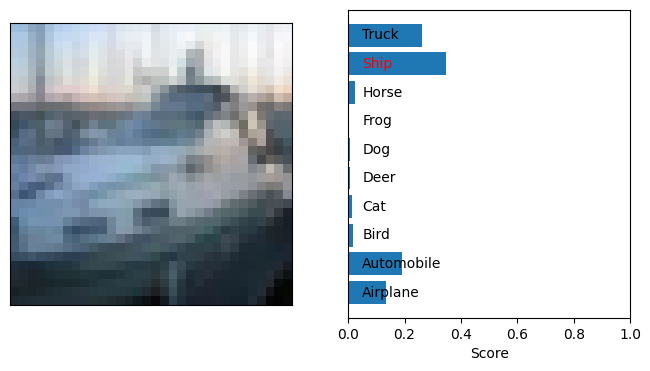

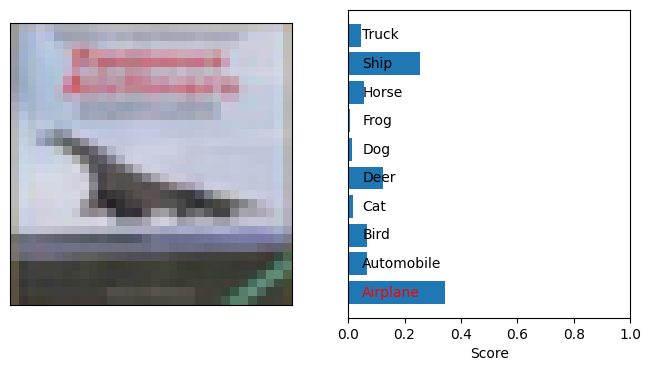

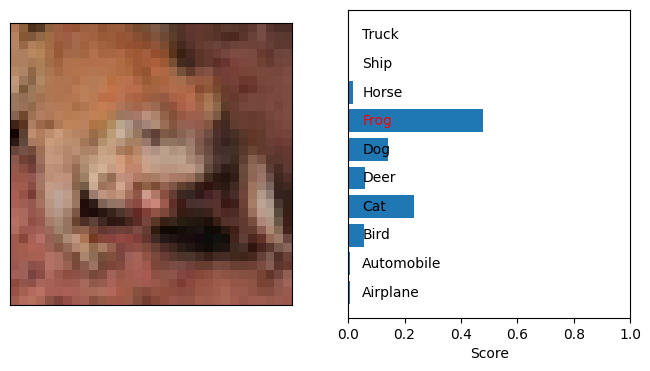

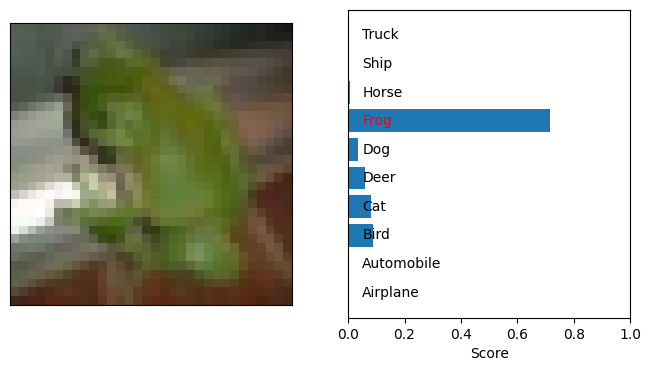

In [12]:
# Task: plot a few examples of correctly and incorrectly classified images.
# Hint: First find the indices of correctly and incorrectly classified images:
m = y_predict_cl == y_test_cl
i0 = np.arange(8000)[~m]  # misclassified images
i1 = np.arange(8000)[m]  # correctly classified images

# original (unnormalized) test images
x_test = x_test[:8000]

# Hint: Now you can use the `plot_prediction` function to plot the images:
# plot first 10 false classifications
for i in i0[0:10]:
    plot_prediction(x_test[i], y_test_onehot[i], y_predict[i])


for i in i1[0:5]:
  plot_prediction(x_test[i], y_test_onehot[i], y_predict[i])


**CNN**
In the second part of this exercise, classify the images with a CNN.


In [19]:
# Hint: this code snipped shows how to define convolution and maxpooling layers. For more information see
# https://keras.io/api/layers/convolution_layers/convolution2d/
# https://keras.io/api/layers/pooling_layers/max_pooling2d/
model = tf.keras.models.Sequential(
    [

    layers.Conv2D(16, kernel_size=(3, 3), padding="same", activation="relu", input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2), strides=2),
    layers.Conv2D(32, kernel_size=(3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2), strides=2),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),

    ],
    name="cnn",
)

print(model.summary())

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │        20,490 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,578 (99.91 KB)

 Trainable params: 25,578 (99.91 KB)

 Non-trainable params: 0 (0.00 B)

None


In [20]:
# ----------------------------------------------------------
# Training
# ----------------------------------------------------------
model.compile(
  loss="categorical_crossentropy",
  optimizer=tf.keras.optimizers.Adam(1e-3),
  metrics=["accuracy"],
)

model.fit(
    x_train_norm, y_train_onehot,
    batch_size=128,
    epochs=40,
    validation_data=(x_valid_norm, y_valid_onehot),
    callbacks=[tf.keras.callbacks.CSVLogger("history_{}.csv".format(model.name))],
)

Epoch 1/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.3888 - loss: 1.7011 - val_accuracy: 0.4700 - val_loss: 1.4603
Epoch 2/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5041 - loss: 1.3998 - val_accuracy: 0.5330 - val_loss: 1.3305
Epoch 3/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5434 - loss: 1.2959 - val_accuracy: 0.5545 - val_loss: 1.2578
Epoch 4/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5645 - loss: 1.2361 - val_accuracy: 0.6005 - val_loss: 1.1533
Epoch 5/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5847 - loss: 1.1866 - val_accuracy: 0.6185 - val_loss: 1.1069
Epoch 6/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6012 - loss: 1.1422 - val_accuracy: 0.6260 - val_loss: 1.0816
Epoch 7/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6084 - loss: 1.1161 - val_accuracy: 0.6250 - val_loss: 1.0660
Epoch 8/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6194 - loss: 1.0907 - val_accuracy: 0

In [21]:
for name, x, y in [("train", x_train_norm, y_train_onehot),
                   ("valid", x_valid_norm, y_valid_onehot),
                   ("test", x_test_norm, y_test_onehot)]:
  loss, acc = model.evaluate(x, y, batch_size=512, verbose=0)
  print(f"{model.name} {name} accuracy: {acc:.3f}")

cnn train accuracy: 0.746
cnn valid accuracy: 0.697
cnn test accuracy: 0.707


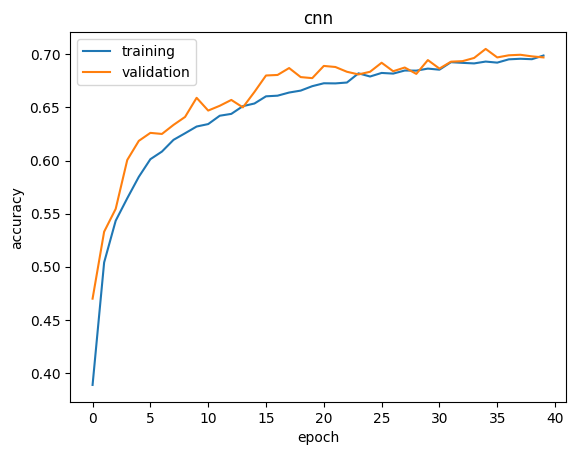

In [22]:
history = np.genfromtxt("history_{}.csv".format(model.name), delimiter=",", names=True)
plt.plot(history["epoch"], history["accuracy"], label="training")
plt.plot(history["epoch"], history["val_accuracy"], label="validation")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title(model.name)
plt.legend()
plt.show()

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step


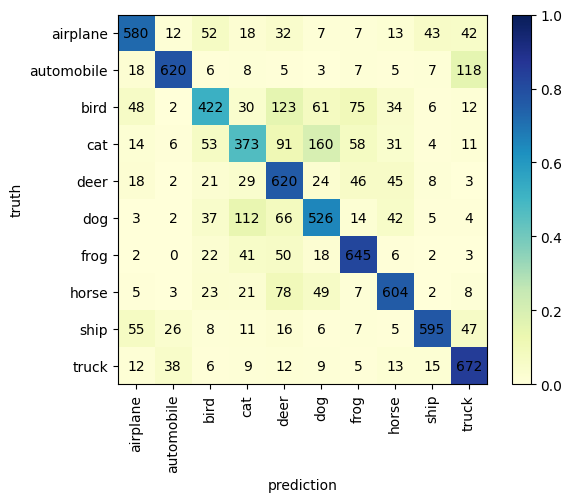

In [23]:
y_predict = model.predict(x_test_norm, batch_size=128)
y_predict_cl = np.argmax(y_predict, axis=1)
y_test_cl = np.argmax(y_test_onehot, axis=1)
plot_confusion(y_test_cl, y_predict_cl)

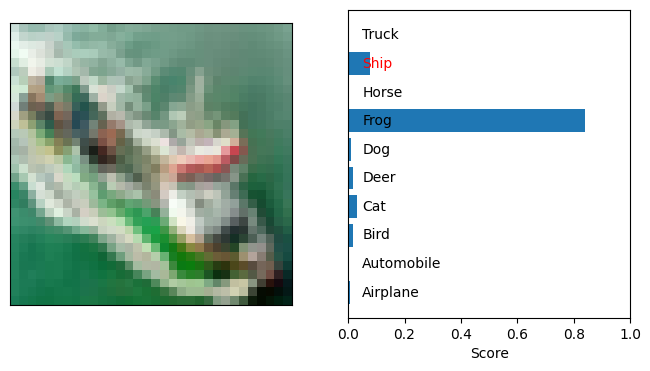

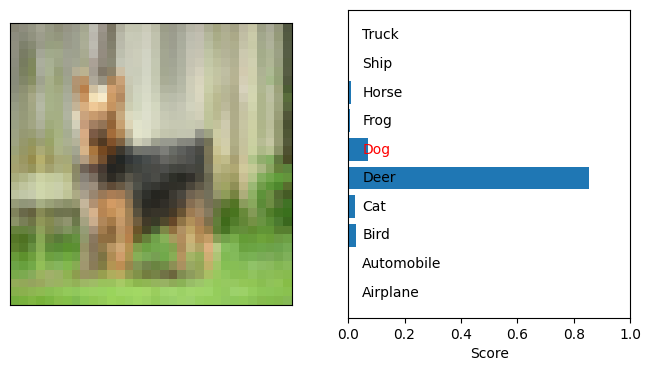

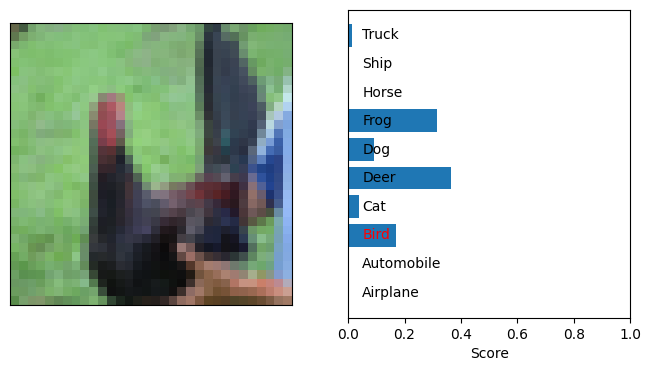

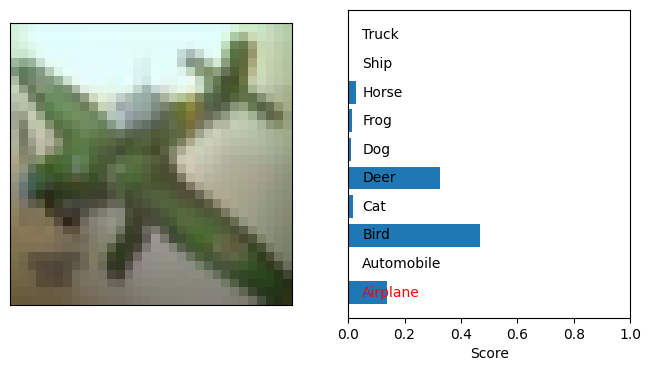

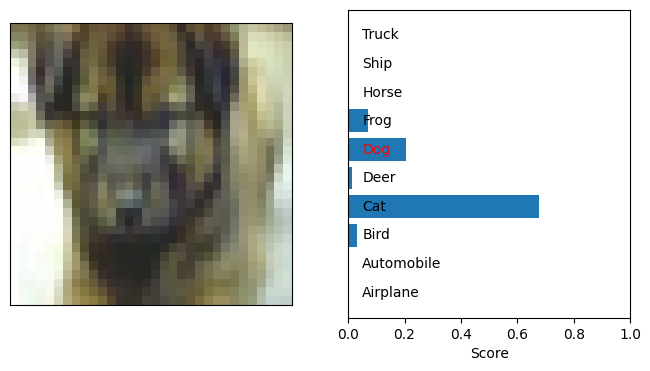

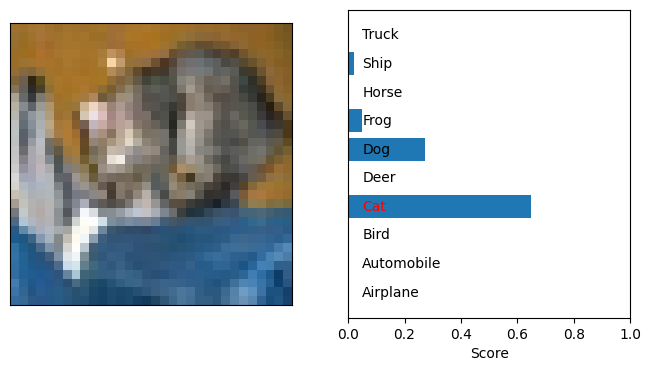

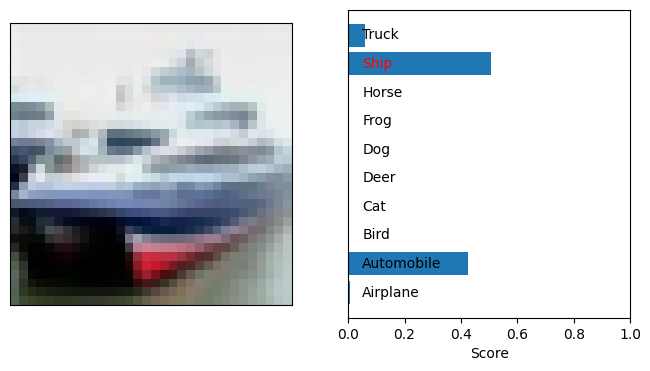

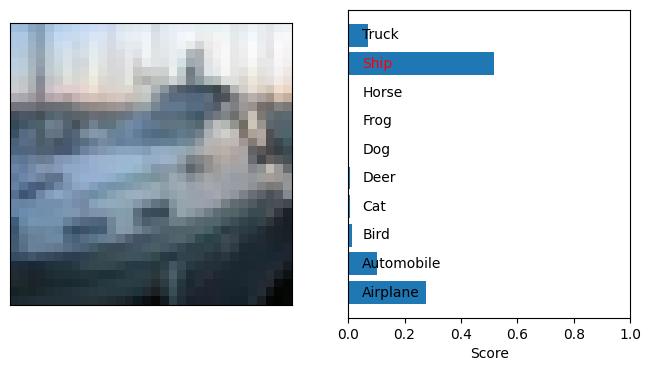

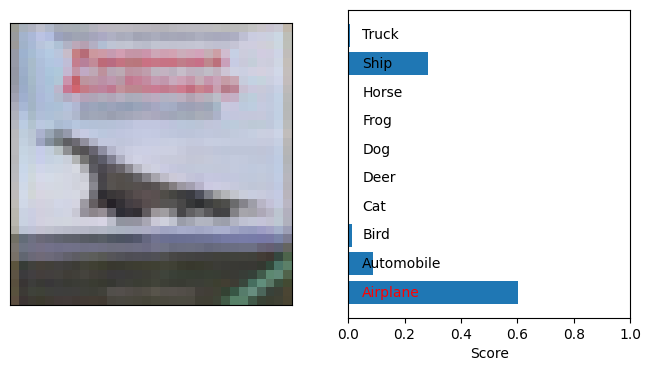

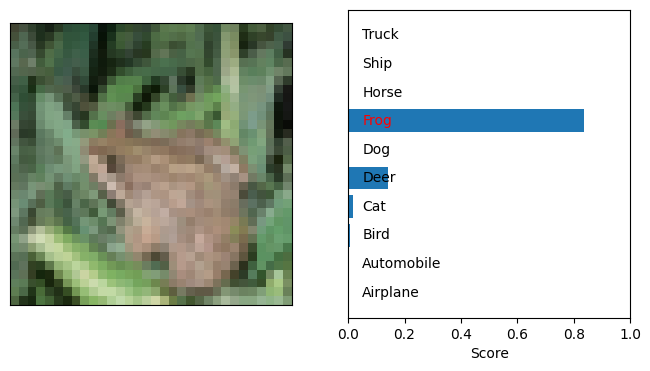

In [24]:
m = y_predict_cl == y_test_cl
i0 = np.arange(8000)[~m]
i1 = np.arange(8000)[m]
for i in i0[0:5]:
  plot_prediction(x_test[i], y_test_onehot[i], y_predict[i])
for i in i1[0:5]:
  plot_prediction(x_test[i], y_test_onehot[i], y_predict[i])

nn

| Data set | Accuracy |
|---|---|
| Training | 0.455 |
| Validation | 0.431 |
| Test | 0.437 |

cnn

| Data set | Accuracy |
|---|---|
| Training | 0.746 |
| Validation | 0.697 |
| Test | 0.707 |



The CNN reaches 70.7 % test accuracy compared with 43.7 % for the fully connected network, because its convolution filters use the spatial structure of the images instead of flattening them. Both models show a small gap between training and validation accuracy, so they overfit only slightly.